# Phase 0-B: WOMD Scenario Protobuf Visualization

This notebook loads a Waymo Open Motion Dataset (WOMD) scenario protobuf from a TFRecord file,
and visualizes every element needed for the nuPlan npz conversion.

## Key WOMD Structure

- **91 timesteps** (0-90) at 10 Hz = 9.1 seconds total
- `current_time_index` = 10 (index of the "current" frame)
  - History: frames 0..10 (11 frames = 1.0s); nuPlan has 21 frames = 2.0s
  - Future: frames 11..90 (80 frames = 8.0s); matches nuPlan exactly
- **Tracks**: Each track has `states[0:91]` with `valid` flag per timestep
- **Map features**: lane, road_line, road_edge, crosswalk, speed_bump, stop_sign, driveway
- **Dynamic map states**: traffic light states per timestep

## Dependencies

```bash
pip install tensorflow protobuf grpcio-tools
```

The first code cell will automatically download and compile the Waymo proto definitions if needed (no manual steps required).

In [65]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.lines import Line2D
from collections import defaultdict
import os
import sys

import tensorflow as tf

# -------------------------------------------------------------------
# Import Waymo proto definitions.
# If waymo-open-dataset pip package is not available (e.g. macOS),
# automatically download scenario.proto & map.proto and compile them.
# We only need these two for motion data — no lidar/camera protos.
# -------------------------------------------------------------------
try:
    from waymo_open_dataset.protos import scenario_pb2
    from waymo_open_dataset.protos import map_pb2
except ImportError:
    _out_dir = os.path.join(os.path.dirname(os.path.abspath("__file__")), "_womd_protos")
    _pb2_flag = os.path.join(_out_dir, "waymo_open_dataset", "protos", "scenario_pb2.py")
    if not os.path.exists(_pb2_flag):
        print("Compiling Waymo proto definitions (one-time setup)...")
        import urllib.request, pathlib, re
        from grpc_tools import protoc as _protoc

        _src = os.path.join(_out_dir, "_src")
        _proto_pkg = os.path.join(_src, "waymo_open_dataset", "protos")
        pathlib.Path(_proto_pkg).mkdir(parents=True, exist_ok=True)

        _base = "https://raw.githubusercontent.com/waymo-research/waymo-open-dataset/master/src/waymo_open_dataset/protos"
        # Only need map.proto (no external deps) and scenario.proto
        urllib.request.urlretrieve(f"{_base}/map.proto", os.path.join(_proto_pkg, "map.proto"))
        urllib.request.urlretrieve(f"{_base}/scenario.proto", os.path.join(_proto_pkg, "scenario.proto"))

        # Patch scenario.proto: remove camera_tokens / compressed_lidar imports & fields
        # (they depend on dataset.proto which pulls in the entire perception stack)
        _sp = os.path.join(_proto_pkg, "scenario.proto")
        _txt = open(_sp).read()
        _txt = re.sub(r'import "waymo_open_dataset/protos/camera_tokens\.proto";\n', '', _txt)
        _txt = re.sub(r'import "waymo_open_dataset/protos/compressed_lidar\.proto";\n', '', _txt)
        _txt = re.sub(r'^\s*repeated CompressedFrameLaserData.*?\n', '', _txt, flags=re.MULTILINE)
        _txt = re.sub(r'^\s*repeated FrameCameraTokens.*?\n', '', _txt, flags=re.MULTILINE)
        # Also remove the comment lines right before those fields
        _txt = re.sub(r'^\s*// Per time step Lidar data\..*?\n', '', _txt, flags=re.MULTILINE)
        _txt = re.sub(r'^\s*// This field is not populated.*?\n', '', _txt, flags=re.MULTILINE)
        _txt = re.sub(r'^\s*// Per time step camera tokens\..*?\n', '', _txt, flags=re.MULTILINE)
        open(_sp, 'w').write(_txt)

        # Create output package structure
        pathlib.Path(os.path.join(_out_dir, "waymo_open_dataset", "protos")).mkdir(parents=True, exist_ok=True)
        pathlib.Path(os.path.join(_out_dir, "waymo_open_dataset", "__init__.py")).touch()
        pathlib.Path(os.path.join(_out_dir, "waymo_open_dataset", "protos", "__init__.py")).touch()

        # Compile
        _protoc.main(["grpc_tools.protoc", f"--proto_path={_src}", f"--python_out={_out_dir}",
                       os.path.join(_proto_pkg, "map.proto"),
                       os.path.join(_proto_pkg, "scenario.proto")])
        print("Done.")

    sys.path.insert(0, _out_dir)
    from waymo_open_dataset.protos import scenario_pb2
    from waymo_open_dataset.protos import map_pb2

%matplotlib inline
plt.rcParams['figure.dpi'] = 120

In [66]:
# ============================================================
# >>> USER CONFIG: Set the path to a WOMD TFRecord file
# ============================================================
TFRECORD_PATH = "/Users/eddiesyn/code/GRID-Planner/samples/training.tfrecord-00459-of-01000"  # e.g. "/path/to/womd/training/training.tfrecord-00000-of-01000"
SCENARIO_INDEX = 0  # Which scenario to load from the file

assert os.path.exists(TFRECORD_PATH), f"TFRecord file not found: {TFRECORD_PATH}"

dataset = tf.data.TFRecordDataset(TFRECORD_PATH)
scenario = None
for idx, raw_record in enumerate(dataset):
    if idx == SCENARIO_INDEX:
        scenario = scenario_pb2.Scenario()
        scenario.ParseFromString(raw_record.numpy())
        break

assert scenario is not None, f"Could not load scenario at index {SCENARIO_INDEX}"
print(f"Scenario ID: {scenario.scenario_id}")
print(f"Number of tracks: {len(scenario.tracks)}")
print(f"SDC track index: {scenario.sdc_track_index}")
print(f"Current time index: {scenario.current_time_index}")
print(f"Timestamps per scenario: {len(scenario.timestamps_seconds)}")
print(f"Number of map features: {len(scenario.map_features)}")
print(f"Number of dynamic map states: {len(scenario.dynamic_map_states)}")

Scenario ID: f4fe5a9237be3d73
Number of tracks: 57
SDC track index: 56
Current time index: 10
Timestamps per scenario: 91
Number of map features: 408
Number of dynamic map states: 91


## Helper Functions

In [ ]:
def get_track_states(track, start=None, end=None):
    """Extract (x, y, heading, vx, vy, length, width, valid) arrays from a track's states."""
    states = track.states[start:end]
    n = len(states)
    x = np.array([s.center_x for s in states])
    y = np.array([s.center_y for s in states])
    heading = np.array([s.heading for s in states])
    vx = np.array([s.velocity_x for s in states])
    vy = np.array([s.velocity_y for s in states])
    length = np.array([s.length for s in states])
    width = np.array([s.width for s in states])
    valid = np.array([s.valid for s in states])
    return x, y, heading, vx, vy, length, width, valid


def get_map_feature_polyline(feature):
    """Extract polyline/polygon points from a map feature.
    
    Works for lane, road_line, road_edge (which have .polyline)
    and crosswalk, speed_bump (which have .polygon).
    """
    if hasattr(feature, 'polyline') and len(feature.polyline) > 0:
        pts = feature.polyline
    elif hasattr(feature, 'polygon') and len(feature.polygon) > 0:
        pts = feature.polygon
    else:
        return np.empty((0, 2))
    return np.array([[p.x, p.y] for p in pts])


def draw_oriented_box(ax, x, y, heading, width, length, color='blue', alpha=0.5, label=None):
    """Draw an oriented bounding box centered at (x, y)."""
    dx = length / 2
    dy = width / 2
    corners_local = np.array([[-dx, -dy], [dx, -dy], [dx, dy], [-dx, dy]])
    cos_h, sin_h = np.cos(heading), np.sin(heading)
    R = np.array([[cos_h, -sin_h], [sin_h, cos_h]])
    corners_global = (R @ corners_local.T).T + np.array([x, y])
    polygon = plt.Polygon(corners_global, closed=True, facecolor=color, 
                          edgecolor='black', alpha=alpha, linewidth=0.5, label=label)
    ax.add_patch(polygon)
    arrow_len = length * 0.5
    ax.arrow(x, y, arrow_len * cos_h, arrow_len * sin_h,
             head_width=0.3, head_length=0.2, fc=color, ec=color, alpha=0.8)


# WOMD object type enum values
# 从官方proto 定义中出现的
OBJECT_TYPE_MAP = {
    1: 'VEHICLE',
    2: 'PEDESTRIAN', 
    3: 'CYCLIST',
    4: 'OTHER',
}

OBJECT_COLORS = {
    'VEHICLE': 'dodgerblue',
    'PEDESTRIAN': 'orange',
    'CYCLIST': 'limegreen',
    'OTHER': 'gray',
}

# Traffic signal state mapping
# From waymo_open_dataset/protos/map.proto TrafficSignalLaneState.State enum
TL_STATE_MAP = {
    0: 'UNKNOWN',           # LANE_STATE_UNKNOWN
    1: 'STOP',              # LANE_STATE_ARROW_STOP
    2: 'CAUTION',           # LANE_STATE_ARROW_CAUTION
    3: 'GO',                # LANE_STATE_ARROW_GO
    4: 'STOP',              # LANE_STATE_STOP
    5: 'CAUTION',           # LANE_STATE_CAUTION
    6: 'GO',                # LANE_STATE_GO
    7: 'STOP',              # LANE_STATE_FLASHING_STOP
    8: 'CAUTION',           # LANE_STATE_FLASHING_CAUTION
}

TL_COLORS = {
    'GO': '#00cc44',
    'CAUTION': '#ffcc00',
    'STOP': '#ff3333',
    'UNKNOWN': '#999999',
}

# Mapping to nuPlan one-hot: [green, yellow, red, unknown]
TL_TO_NUPLAN_ONEHOT = {
    'GO': [1, 0, 0, 0],
    'CAUTION': [0, 1, 0, 0],
    'STOP': [0, 0, 1, 0],
    'UNKNOWN': [0, 0, 0, 1],
}

## 1. Parse Map Features

Build lookup tables for all map features by ID and type.

In [ ]:
# Build a dictionary of all map features by ID
map_features_by_id = {}
lanes_list = []          # LaneCenter features
road_lines_list = []     # RoadLine features
road_edges_list = []     # RoadEdge features
crosswalks_list = []     # Crosswalk features
stop_signs_list = []     # StopSign features
speed_bumps_list = []    # SpeedBump features

feature_type_counts = defaultdict(int)

for mf in scenario.map_features:
    feature_id = mf.id
    map_features_by_id[feature_id] = mf
    
    if mf.HasField('lane'):
        lanes_list.append(mf)
        feature_type_counts['lane'] += 1
    elif mf.HasField('road_line'):
        road_lines_list.append(mf)
        feature_type_counts['road_line'] += 1
    elif mf.HasField('road_edge'):
        road_edges_list.append(mf)
        feature_type_counts['road_edge'] += 1
    elif mf.HasField('crosswalk'):
        crosswalks_list.append(mf)
        feature_type_counts['crosswalk'] += 1
    elif mf.HasField('stop_sign'):
        stop_signs_list.append(mf)
        feature_type_counts['stop_sign'] += 1
    elif mf.HasField('speed_bump'):
        speed_bumps_list.append(mf)
        feature_type_counts['speed_bump'] += 1
    else:
        feature_type_counts['other'] += 1

print("Map feature counts:")
for k, v in sorted(feature_type_counts.items()):
    print(f"  {k}: {v}")

Map feature counts:
  crosswalk: 12
  lane: 290
  other: 7
  road_edge: 50
  road_line: 41
  speed_bump: 8


## 2. SDC (Self-Driving Car) Trajectory

In [69]:
sdc_track = scenario.tracks[scenario.sdc_track_index]
ct = scenario.current_time_index  # typically 10
# 增加 一个assert
assert ct == 10

sdc_x, sdc_y, sdc_h, sdc_vx, sdc_vy, sdc_len, sdc_w, sdc_valid = get_track_states(sdc_track)

print(f"SDC track object type: {OBJECT_TYPE_MAP.get(sdc_track.object_type, 'UNKNOWN')}")
print(f"Current time index: {ct}")
print(f"Total timesteps: {len(sdc_track.states)}")
print(f"History frames: 0..{ct} ({ct+1} frames = {ct*0.1:.1f}s)")
print(f"Future frames: {ct+1}..{len(sdc_track.states)-1} ({len(sdc_track.states)-ct-1} frames = {(len(sdc_track.states)-ct-1)*0.1:.1f}s)")
print(f"\nSDC at current time:")
print(f"  Position: ({sdc_x[ct]:.2f}, {sdc_y[ct]:.2f})")
print(f"  Heading: {sdc_h[ct]:.4f} rad")
print(f"  Velocity: ({sdc_vx[ct]:.2f}, {sdc_vy[ct]:.2f}) m/s")
print(f"  Size: length={sdc_len[ct]:.2f}, width={sdc_w[ct]:.2f}")

# Check valid flags
n_valid_past = sdc_valid[:ct+1].sum()
n_valid_future = sdc_valid[ct+1:].sum()
print(f"\n  Valid past frames: {n_valid_past}/{ct+1}")
print(f"  Valid future frames: {n_valid_future}/{len(sdc_track.states)-ct-1}")
print(f"\n  NOTE: WOMD history = {ct+1} frames ({ct*0.1:.1f}s), nuPlan history = 21 frames (2.0s)")
print(f"  => Need to pad {21 - (ct+1)} frames by repeating earliest valid state")

SDC track object type: VEHICLE
Current time index: 10
Total timesteps: 91
History frames: 0..10 (11 frames = 1.0s)
Future frames: 11..90 (80 frames = 8.0s)

SDC at current time:
  Position: (-8725.75, -3450.22)
  Heading: -0.0045 rad
  Velocity: (20.20, -0.12) m/s
  Size: length=5.29, width=2.33

  Valid past frames: 11/11
  Valid future frames: 80/80

  NOTE: WOMD history = 11 frames (1.0s), nuPlan history = 21 frames (2.0s)
  => Need to pad 10 frames by repeating earliest valid state


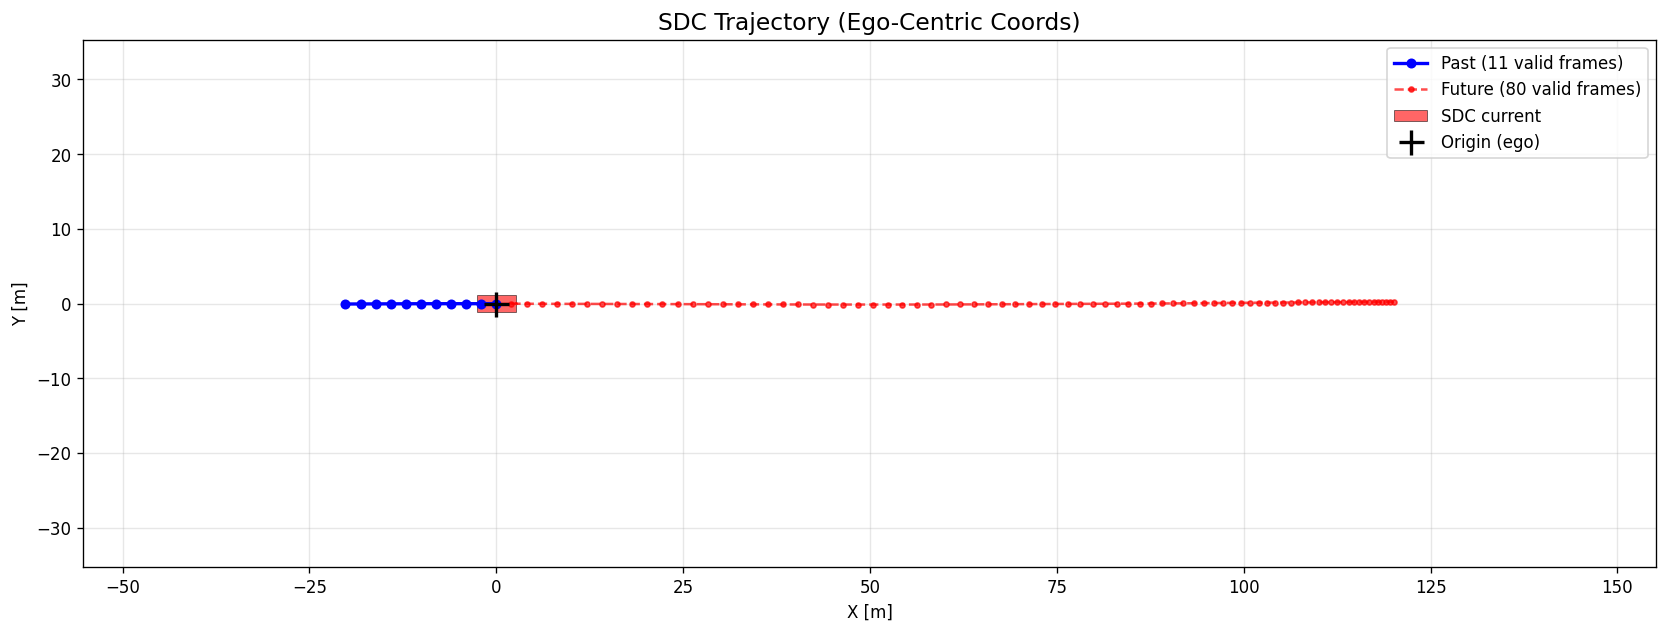

In [80]:
def _auto_zoom(ax, all_xs, all_ys, margin_ratio=0.25, min_margin=10.0):
    """Set xlim/ylim based on data extent with comfortable margins."""
    x_min, x_max = min(all_xs), max(all_xs)
    y_min, y_max = min(all_ys), max(all_ys)
    x_range = x_max - x_min
    y_range = y_max - y_min
    margin = max(min_margin, max(x_range, y_range) * margin_ratio)
    ax.set_xlim(x_min - margin, x_max + margin)
    ax.set_ylim(y_min - margin, y_max + margin)

past_mask = sdc_valid[:ct+1]
future_mask = sdc_valid[ct+1:]
all_valid = sdc_valid.astype(bool)

ego_x, ego_y, ego_h = sdc_x[ct], sdc_y[ct], sdc_h[ct]
cos_h, sin_h = np.cos(-ego_h), np.sin(-ego_h)

def to_ego_frame(x, y):
    dx = x - ego_x
    dy = y - ego_y
    local_x = dx * cos_h - dy * sin_h
    local_y = dx * sin_h + dy * cos_h
    return local_x, local_y

sdc_lx, sdc_ly = to_ego_frame(sdc_x, sdc_y)

fig, ax = plt.subplots(1, 1, figsize=(14, 14))
ax.set_aspect('equal')
ax.set_title('SDC Trajectory (Ego-Centric Coords)', fontsize=14)

ax.plot(sdc_lx[:ct+1][past_mask], sdc_ly[:ct+1][past_mask], 'b-o', markersize=5,
        linewidth=2, label=f'Past ({past_mask.sum()} valid frames)')
ax.plot(sdc_lx[ct+1:][future_mask], sdc_ly[ct+1:][future_mask], 'r--o', markersize=3,
        linewidth=1.5, label=f'Future ({future_mask.sum()} valid frames)', alpha=0.7)

local_heading = sdc_h[ct] - ego_h
draw_oriented_box(ax, sdc_lx[ct], sdc_ly[ct], local_heading, sdc_w[ct], sdc_len[ct],
                  color='red', alpha=0.6, label='SDC current')
ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2, label='Origin (ego)')

_auto_zoom(ax, sdc_lx[all_valid].tolist() + [0.0], sdc_ly[all_valid].tolist() + [0.0])

ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Other Agent Tracks

In [76]:
# Categorize tracks by object type
tracks_by_type = defaultdict(list)
for i, track in enumerate(scenario.tracks):
    if i == scenario.sdc_track_index:
        continue
    obj_type = OBJECT_TYPE_MAP.get(track.object_type, 'OTHER')
    # Only include tracks valid at current time
    if track.states[ct].valid:
        tracks_by_type[obj_type].append((i, track))

print("Agent counts (valid at current time, excluding SDC):")
for t, tracks in sorted(tracks_by_type.items()):
    print(f"  {t}: {len(tracks)}")
total_valid = sum(len(v) for v in tracks_by_type.values())
print(f"  Total: {total_valid}")
print(f"  (nuPlan selects top 32 by distance, max 10 ped+bike)")

Agent counts (valid at current time, excluding SDC):
  VEHICLE: 16
  Total: 16
  (nuPlan selects top 32 by distance, max 10 ped+bike)


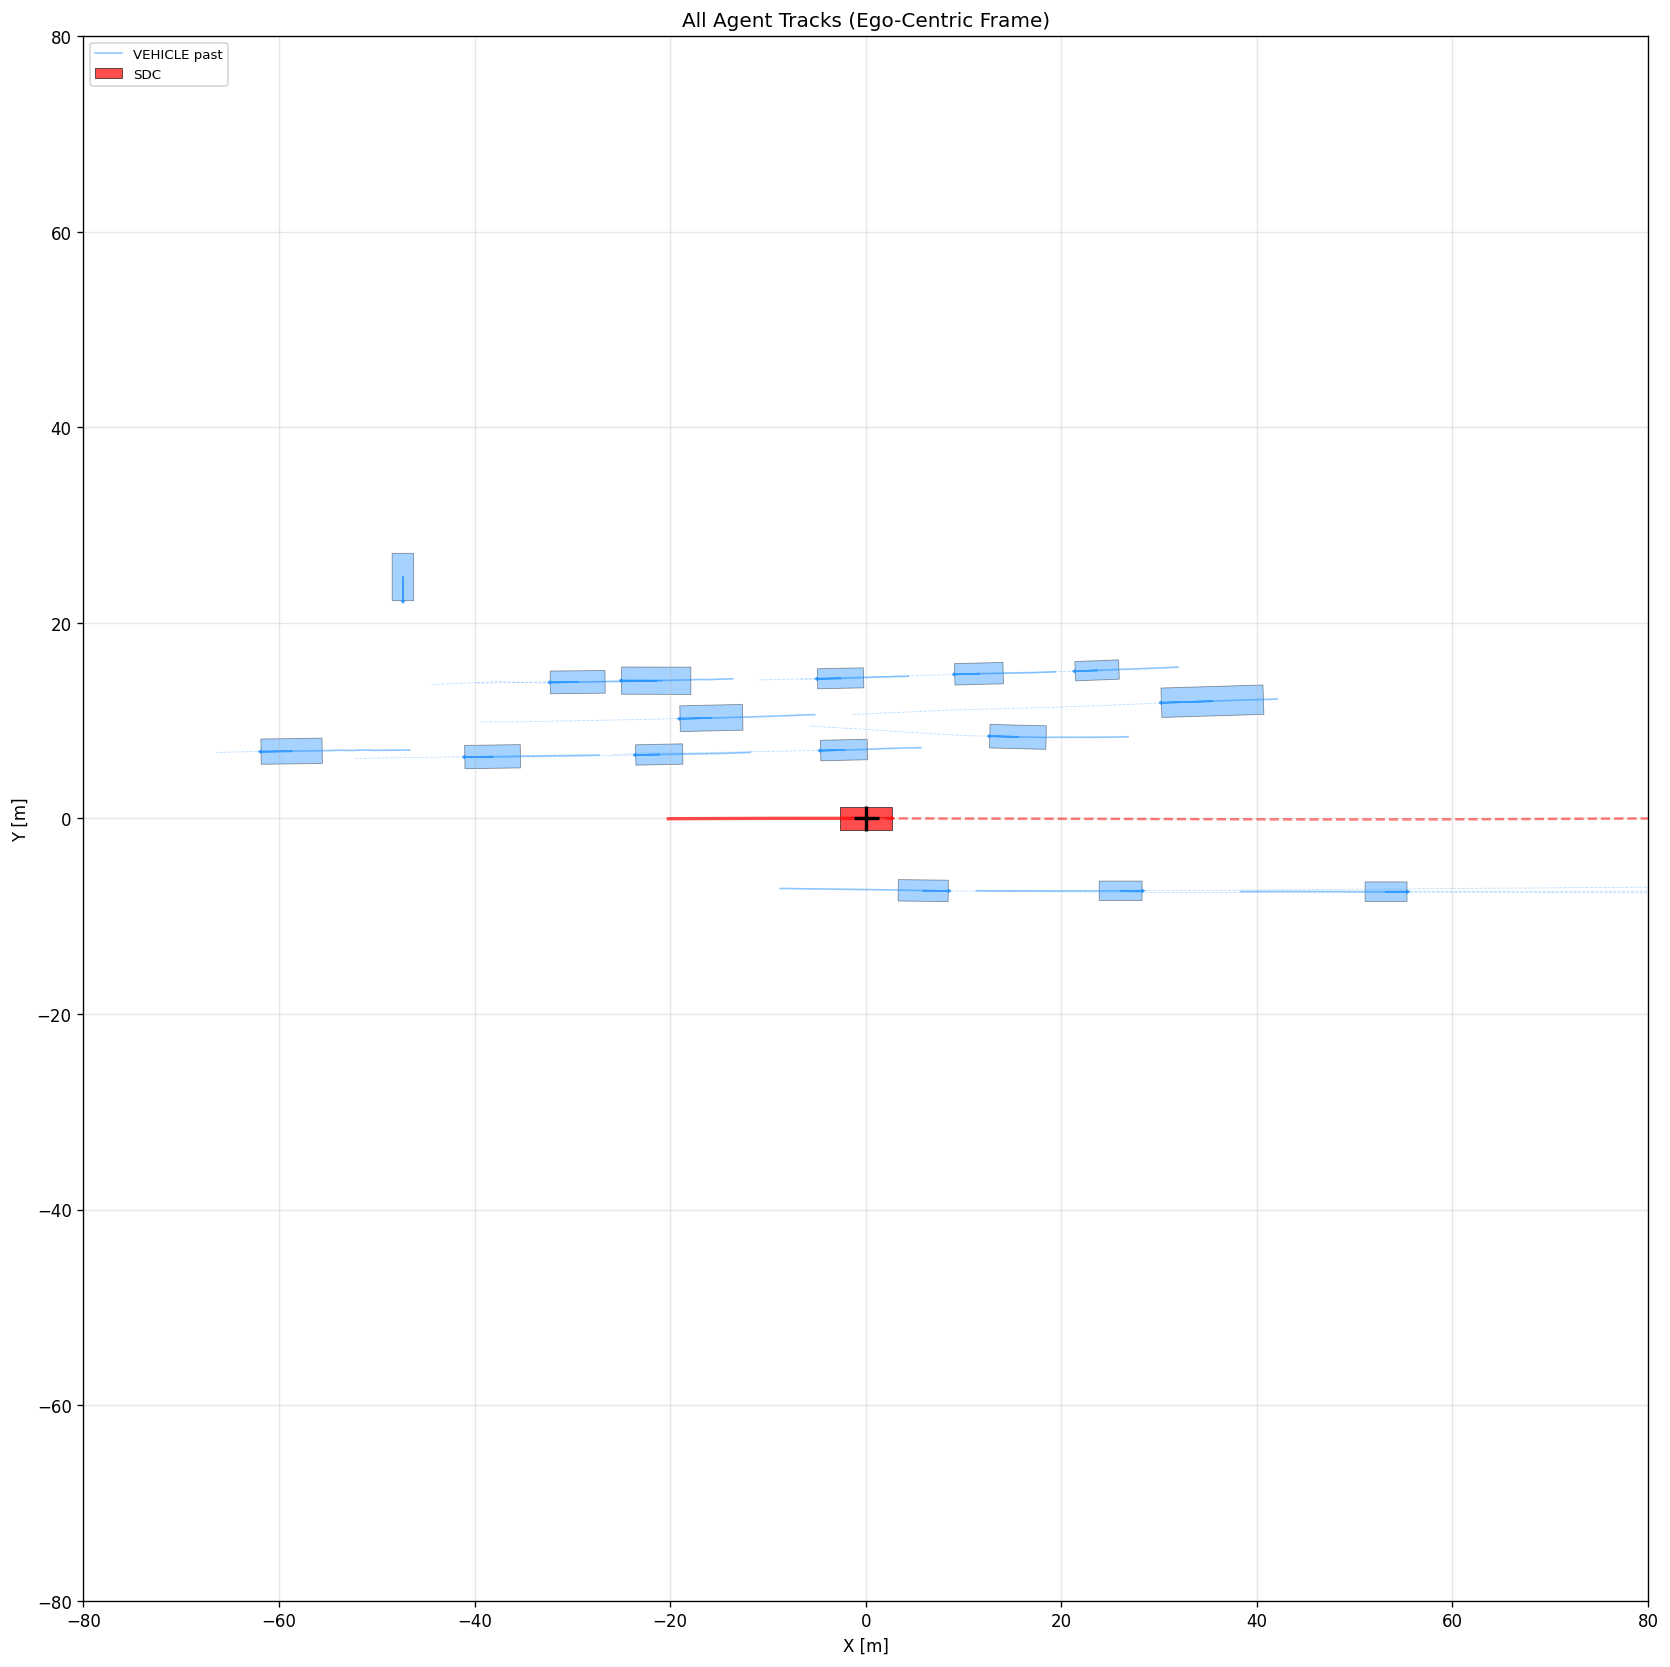

In [77]:
fig, ax = plt.subplots(1, 1, figsize=(14, 14))
ax.set_aspect('equal')
ax.set_title('All Agent Tracks (Ego-Centric Frame)')

legend_added = set()

# Plot all agents
for obj_type, tracks in tracks_by_type.items():
    color = OBJECT_COLORS.get(obj_type, 'gray')
    for track_idx, track in tracks:
        x, y, h, vx, vy, l, w, valid = get_track_states(track)
        lx, ly = to_ego_frame(x, y)
        
        # Only show agents within 80m of ego at current time
        if np.sqrt(lx[ct]**2 + ly[ct]**2) > 80:
            continue
        
        # Past
        past_v = valid[:ct+1]
        lbl = f'{obj_type} past' if obj_type not in legend_added else None
        ax.plot(lx[:ct+1][past_v], ly[:ct+1][past_v], '-', color=color,
                linewidth=1.0, alpha=0.5, label=lbl)
        
        # Current box
        if valid[ct]:
            local_heading = h[ct] - ego_h
            draw_oriented_box(ax, lx[ct], ly[ct], local_heading, w[ct], l[ct],
                              color=color, alpha=0.4)
        
        # Future (dashed)
        fut_v = valid[ct+1:]
        if fut_v.any():
            ax.plot(lx[ct+1:][fut_v], ly[ct+1:][fut_v], '--', color=color,
                    linewidth=0.5, alpha=0.3)
        
        legend_added.add(obj_type)

# SDC
ax.plot(sdc_lx[:ct+1][past_mask], sdc_ly[:ct+1][past_mask], 'r-', linewidth=2, alpha=0.7)
ax.plot(sdc_lx[ct+1:][future_mask], sdc_ly[ct+1:][future_mask], 'r--', linewidth=1.5, alpha=0.5)
draw_oriented_box(ax, 0, 0, 0, sdc_w[ct], sdc_len[ct], color='red', alpha=0.7, label='SDC')

ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2)
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.legend(fontsize=8, loc='upper left')
ax.set_xlim(-80, 80)
ax.set_ylim(-80, 80)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Lane Center Polylines + Boundary Resolution

**Critical verification**: WOMD lane boundaries are specified via `BoundarySegment` references that
point to `RoadLine` or `RoadEdge` features. We need to:
1. For each lane, iterate over `left_boundaries` and `right_boundaries`
2. For each `BoundarySegment`, look up the referenced `RoadLine`/`RoadEdge` by `boundary_feature_id`
3. Extract the sub-polyline from `lane_start_index` to `lane_end_index`
4. Concatenate segments to form the full left/right boundary

In [78]:
def resolve_lane_boundaries(lane_feature, map_features_by_id):
    """Resolve boundary segments into polylines for a lane.
    
    Args:
        lane_feature: A map feature with HasField('lane') == True
        map_features_by_id: Dict mapping feature_id -> map feature proto
    
    Returns:
        left_boundary_pts: np.array of shape (N, 2) or None
        right_boundary_pts: np.array of shape (N, 2) or None
        boundary_info: dict with diagnostic info
    """
    lane = lane_feature.lane
    info = {'left_segments': len(lane.left_boundaries), 'right_segments': len(lane.right_boundaries),
            'left_resolved': 0, 'right_resolved': 0, 'left_failed': 0, 'right_failed': 0}
    
    def resolve_side(boundary_segments):
        all_pts = []
        resolved = 0
        failed = 0
        for seg in boundary_segments:
            feat_id = seg.boundary_feature_id
            if feat_id not in map_features_by_id:
                failed += 1
                continue
            ref_feat = map_features_by_id[feat_id]
            # Get the polyline from the referenced feature
            if ref_feat.HasField('road_line'):
                polyline = ref_feat.road_line.polyline
            elif ref_feat.HasField('road_edge'):
                polyline = ref_feat.road_edge.polyline
            else:
                failed += 1
                continue
            
            # NOTE: lane_start_index / lane_end_index are indices into the
            # LANE CENTER polyline (indicating which lane points this boundary
            # covers), NOT indices into the boundary polyline.
            # We take the entire boundary polyline for each segment.
            pts = np.array([[p.x, p.y] for p in polyline])
            if len(pts) > 0:
                all_pts.append(pts)
                resolved += 1
            else:
                failed += 1
        
        if len(all_pts) > 0:
            return np.concatenate(all_pts, axis=0), resolved, failed
        return None, resolved, failed
    
    left_pts, info['left_resolved'], info['left_failed'] = resolve_side(lane.left_boundaries)
    right_pts, info['right_resolved'], info['right_failed'] = resolve_side(lane.right_boundaries)
    
    return left_pts, right_pts, info


# Test boundary resolution on a few lanes
print("Testing boundary resolution on first 5 lanes:")
for mf in lanes_list[:5]:
    left, right, info = resolve_lane_boundaries(mf, map_features_by_id)
    lane_pts = get_map_feature_polyline(mf.lane)
    print(f"\n  Lane {mf.id}:")
    print(f"    Center polyline: {lane_pts.shape[0]} points")
    print(f"    Left boundary: {info['left_segments']} segments, {info['left_resolved']} resolved, "
          f"{info['left_failed']} failed -> {left.shape[0] if left is not None else 0} points")
    print(f"    Right boundary: {info['right_segments']} segments, {info['right_resolved']} resolved, "
          f"{info['right_failed']} failed -> {right.shape[0] if right is not None else 0} points")
    
    # Check if speed limit is available
    if mf.lane.speed_limit_mph > 0:
        print(f"    Speed limit: {mf.lane.speed_limit_mph} mph = {mf.lane.speed_limit_mph * 0.44704:.1f} m/s")
    else:
        print(f"    Speed limit: not set")

Testing boundary resolution on first 5 lanes:

  Lane 173:
    Center polyline: 46 points
    Left boundary: 1 segments, 1 resolved, 0 failed -> 100 points
    Right boundary: 1 segments, 1 resolved, 0 failed -> 98 points
    Speed limit: 15.0 mph = 6.7 m/s

  Lane 187:
    Center polyline: 24 points
    Left boundary: 0 segments, 0 resolved, 0 failed -> 0 points
    Right boundary: 2 segments, 2 resolved, 0 failed -> 240 points
    Speed limit: 15.0 mph = 6.7 m/s

  Lane 188:
    Center polyline: 19 points
    Left boundary: 0 segments, 0 resolved, 0 failed -> 0 points
    Right boundary: 1 segments, 1 resolved, 0 failed -> 137 points
    Speed limit: 15.0 mph = 6.7 m/s

  Lane 190:
    Center polyline: 28 points
    Left boundary: 0 segments, 0 resolved, 0 failed -> 0 points
    Right boundary: 1 segments, 1 resolved, 0 failed -> 137 points
    Speed limit: 15.0 mph = 6.7 m/s

  Lane 191:
    Center polyline: 12 points
    Left boundary: 0 segments, 0 resolved, 0 failed -> 0 points
 

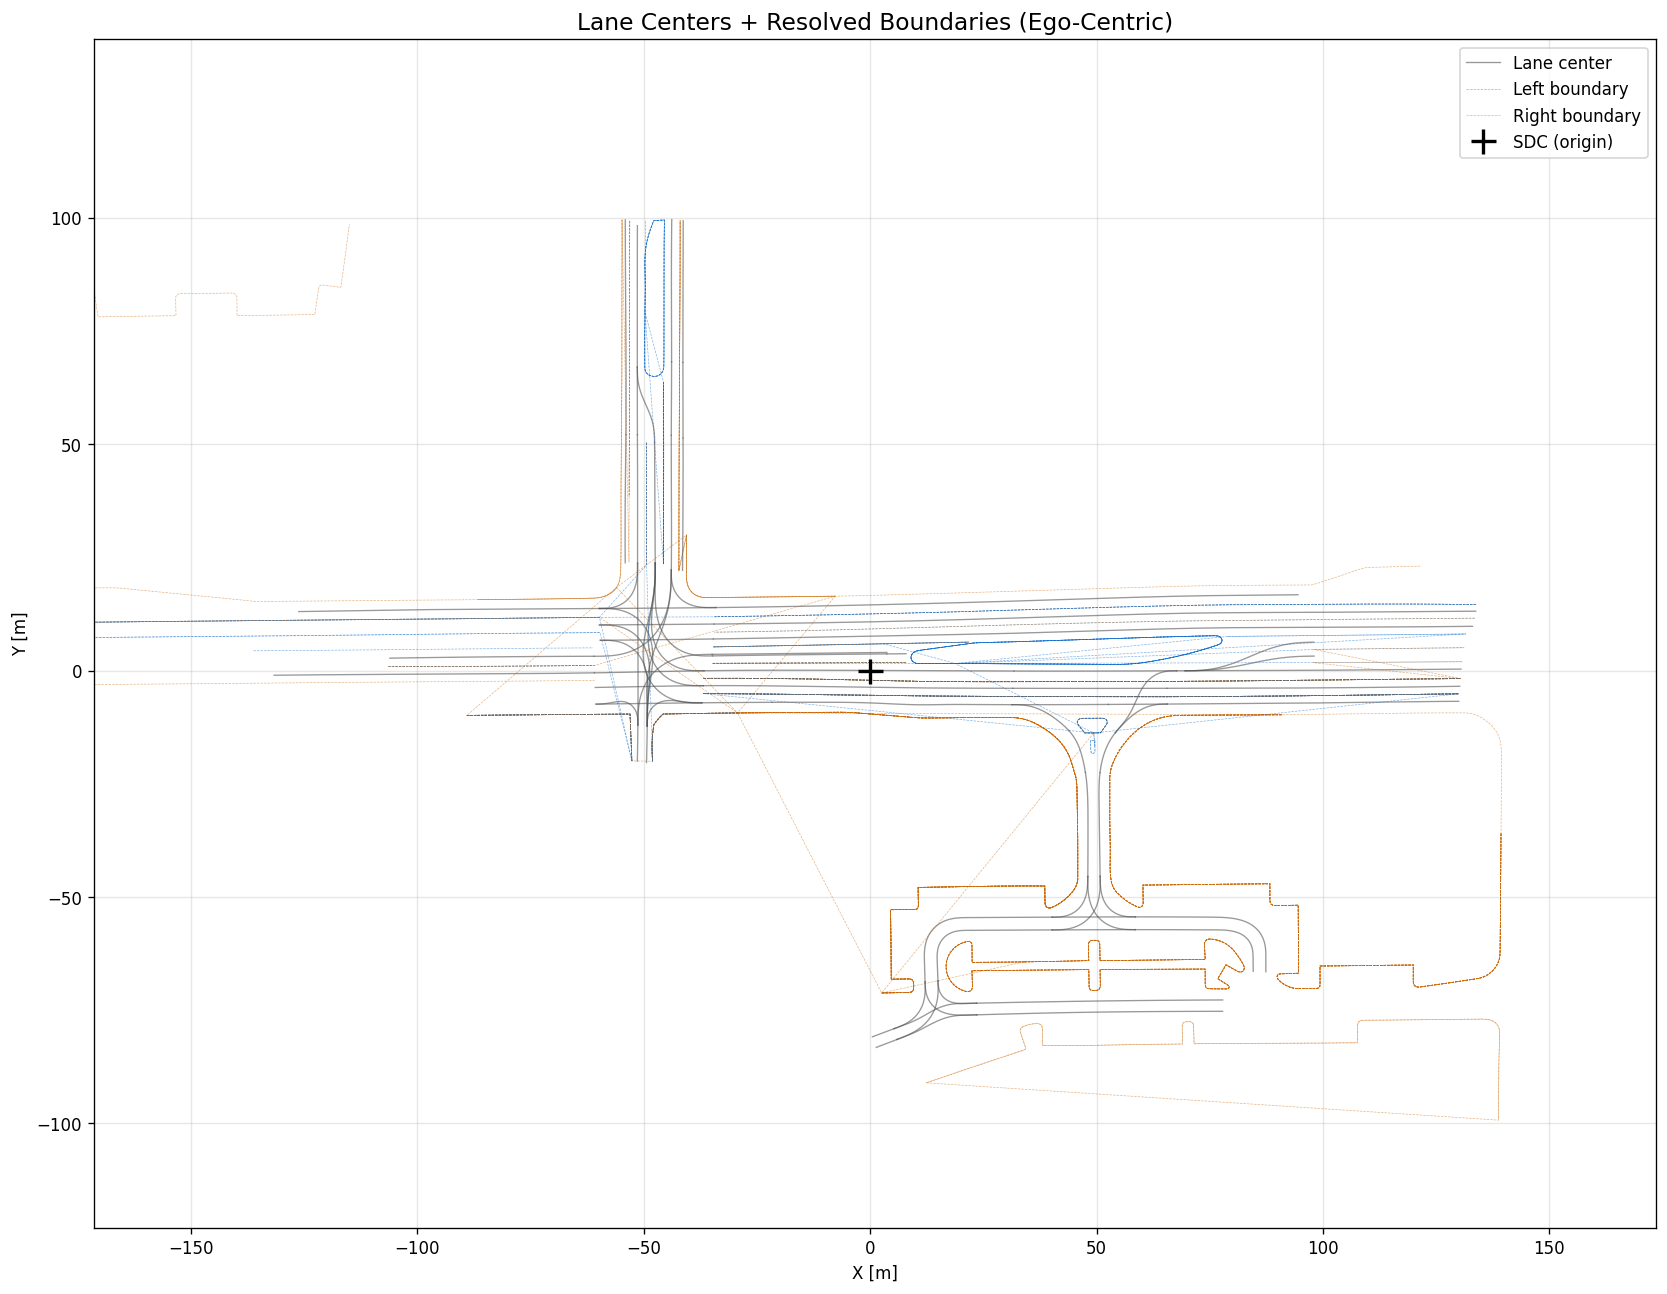

In [81]:
sdc_pos = np.array([sdc_x[ct], sdc_y[ct]])

fig, ax = plt.subplots(1, 1, figsize=(14, 14))
ax.set_aspect('equal')
ax.set_title('Lane Centers + Resolved Boundaries (Ego-Centric)', fontsize=14)

all_xs, all_ys = [0.0], [0.0]
center_added, left_added, right_added = False, False, False

for mf in lanes_list:
    lane_pts = get_map_feature_polyline(mf.lane)
    if np.linalg.norm(lane_pts.mean(axis=0) - sdc_pos) > 100:
        continue

    lx, ly = to_ego_frame(lane_pts[:, 0], lane_pts[:, 1])
    lbl_c = 'Lane center' if not center_added else None
    ax.plot(lx, ly, '-', color='#555555', linewidth=0.8, alpha=0.6, label=lbl_c)
    center_added = True
    all_xs.extend(lx.tolist())
    all_ys.extend(ly.tolist())

    left, right, _ = resolve_lane_boundaries(mf, map_features_by_id)
    if left is not None:
        blx, bly = to_ego_frame(left[:, 0], left[:, 1])
        lbl_l = 'Left boundary' if not left_added else None
        ax.plot(blx, bly, '--', color='#0066cc', linewidth=0.4, alpha=0.5, label=lbl_l)
        left_added = True
    if right is not None:
        brx, bry = to_ego_frame(right[:, 0], right[:, 1])
        lbl_r = 'Right boundary' if not right_added else None
        ax.plot(brx, bry, '--', color='#cc6600', linewidth=0.4, alpha=0.5, label=lbl_r)
        right_added = True

ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2, label='SDC (origin)')

x_min, x_max = min(all_xs), max(all_xs)
y_min, y_max = min(all_ys), max(all_ys)
margin = max(10.0, max(x_max - x_min, y_max - y_min) * 0.15)
ax.set_xlim(x_min - margin, x_max + margin)
ax.set_ylim(y_min - margin, y_max + margin)

ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 4.1 Boundary Segment Continuity Analysis

Check if multiple boundary segments per lane are contiguous (head-to-tail connected).

In [82]:
print("Boundary segment continuity analysis:")
print("="*60)

multi_seg_count = 0
gap_count = 0
total_lanes_checked = 0

for mf in lanes_list[:50]:  # Check first 50 lanes
    lane = mf.lane
    for side_name, boundaries in [('left', lane.left_boundaries), ('right', lane.right_boundaries)]:
        if len(boundaries) <= 1:
            continue
        multi_seg_count += 1
        
        # Check if consecutive boundary segments are contiguous:
        # Compare the LAST point of boundary polyline 1 with the FIRST point of boundary polyline 2
        for s_idx in range(len(boundaries) - 1):
            seg1 = boundaries[s_idx]
            seg2 = boundaries[s_idx + 1]
            
            feat1 = map_features_by_id.get(seg1.boundary_feature_id)
            feat2 = map_features_by_id.get(seg2.boundary_feature_id)
            if feat1 is None or feat2 is None:
                continue
            
            poly1 = feat1.road_line.polyline if feat1.HasField('road_line') else feat1.road_edge.polyline
            poly2 = feat2.road_line.polyline if feat2.HasField('road_line') else feat2.road_edge.polyline
            
            if len(poly1) == 0 or len(poly2) == 0:
                continue
            
            # Last point of first boundary polyline vs first point of second
            end_pt = np.array([poly1[-1].x, poly1[-1].y])
            start_pt = np.array([poly2[0].x, poly2[0].y])
            gap = np.linalg.norm(end_pt - start_pt)
            
            if gap > 1.0:
                gap_count += 1
                if gap_count <= 5:
                    print(f"  Lane {mf.id} {side_name}: gap of {gap:.2f}m between segments {s_idx} and {s_idx+1}")
                    # Also show lane_start/end_index for context
                    print(f"    seg{s_idx}: lane_idx [{seg1.lane_start_index}:{seg1.lane_end_index}], "
                          f"boundary feat {seg1.boundary_feature_id} ({len(poly1)} pts)")
                    print(f"    seg{s_idx+1}: lane_idx [{seg2.lane_start_index}:{seg2.lane_end_index}], "
                          f"boundary feat {seg2.boundary_feature_id} ({len(poly2)} pts)")
    total_lanes_checked += 1

print(f"\nSummary ({total_lanes_checked} lanes checked):")
print(f"  Multi-segment boundaries: {multi_seg_count}")
print(f"  Boundaries with gaps > 1m: {gap_count}")
print(f"  => {'Segments are mostly contiguous' if gap_count < 5 else 'Some gaps exist (expected for intersection lanes)'}")

Boundary segment continuity analysis:
  Lane 187 right: gap of 59.85m between segments 0 and 1
    seg0: lane_idx [0:3], boundary feat 21 (137 pts)
    seg1: lane_idx [19:23], boundary feat 16 (103 pts)
  Lane 197 right: gap of 47.31m between segments 0 and 1
    seg0: lane_idx [0:5], boundary feat 21 (137 pts)
    seg1: lane_idx [22:23], boundary feat 70 (98 pts)
  Lane 200 right: gap of 21.58m between segments 0 and 1
    seg0: lane_idx [0:10], boundary feat 21 (137 pts)
    seg1: lane_idx [32:35], boundary feat 75 (49 pts)
  Lane 203 right: gap of 16.75m between segments 0 and 1
    seg0: lane_idx [0:4], boundary feat 16 (103 pts)
    seg1: lane_idx [20:25], boundary feat 21 (137 pts)
  Lane 240 right: gap of 40.43m between segments 0 and 1
    seg0: lane_idx [0:3], boundary feat 16 (103 pts)
    seg1: lane_idx [79:84], boundary feat 35 (56 pts)

Summary (50 lanes checked):
  Multi-segment boundaries: 17
  Boundaries with gaps > 1m: 14
  => Some gaps exist (expected for intersection

## 5. Traffic Light States

In [83]:
# Get traffic light states at current time
tl_at_current = {}
if ct < len(scenario.dynamic_map_states):
    dms = scenario.dynamic_map_states[ct]
    for lane_state in dms.lane_states:
        state_name = TL_STATE_MAP.get(lane_state.state, 'UNKNOWN')
        tl_at_current[lane_state.lane] = {
            'state': state_name,
            'raw_state': lane_state.state,
            'stop_point': (lane_state.stop_point.x, lane_state.stop_point.y) 
                          if lane_state.HasField('stop_point') else None
        }

tl_state_counts = defaultdict(int)
for info in tl_at_current.values():
    tl_state_counts[info['state']] += 1

print(f"Traffic light states at current time (t={ct}):")
print(f"  Total lanes with TL: {len(tl_at_current)}")
for state, count in sorted(tl_state_counts.items()):
    print(f"  {state}: {count}")

print(f"\nMapping to nuPlan one-hot [green, yellow, red, unknown]:")
for state in ['GO', 'CAUTION', 'STOP', 'UNKNOWN']:
    print(f"  {state} -> {TL_TO_NUPLAN_ONEHOT[state]}")
    
# Show raw enum values
raw_state_counts = defaultdict(int)
for info in tl_at_current.values():
    raw_state_counts[info['raw_state']] += 1
print(f"\nRaw state enum distribution:")
raw_names = {
    0: 'LANE_STATE_UNKNOWN', 1: 'LANE_STATE_ARROW_STOP', 2: 'LANE_STATE_ARROW_CAUTION',
    3: 'LANE_STATE_ARROW_GO', 4: 'LANE_STATE_STOP', 5: 'LANE_STATE_CAUTION',
    6: 'LANE_STATE_GO', 7: 'LANE_STATE_FLASHING_STOP', 8: 'LANE_STATE_FLASHING_CAUTION'
}
for raw, count in sorted(raw_state_counts.items()):
    name = raw_names.get(raw, f'STATE_{raw}')
    mapped = TL_STATE_MAP.get(raw, 'UNKNOWN')
    print(f"  {raw} ({name}) -> {mapped}: {count}")

Traffic light states at current time (t=10):
  Total lanes with TL: 6
  GO: 4
  UNKNOWN: 2

Mapping to nuPlan one-hot [green, yellow, red, unknown]:
  GO -> [1, 0, 0, 0]
  CAUTION -> [0, 1, 0, 0]
  STOP -> [0, 0, 1, 0]
  UNKNOWN -> [0, 0, 0, 1]

Raw state enum distribution:
  0 (LANE_STATE_UNKNOWN) -> UNKNOWN: 2
  6 (LANE_STATE_GO) -> GO: 4


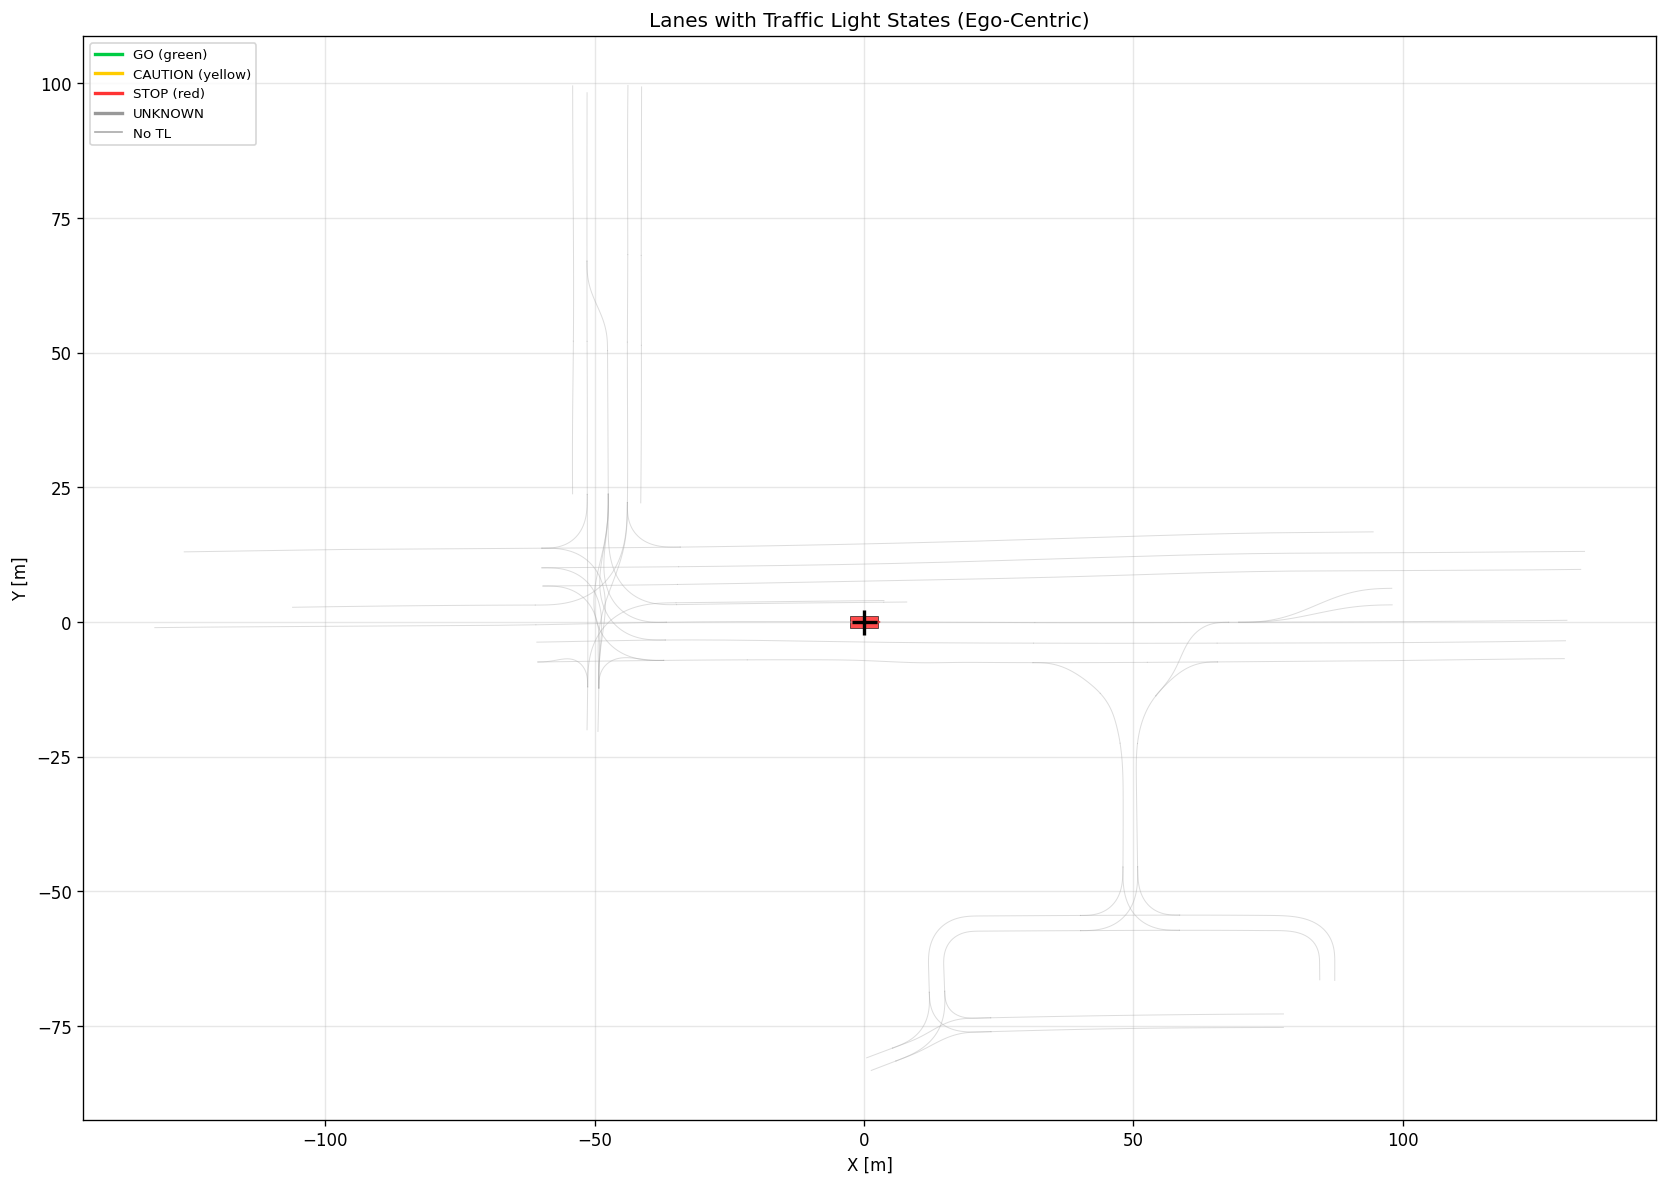

In [84]:
fig, ax = plt.subplots(1, 1, figsize=(14, 14))
ax.set_aspect('equal')
ax.set_title('Lanes with Traffic Light States (Ego-Centric)')

# Plot all lanes, colored by traffic light state
for mf in lanes_list:
    lane_pts = get_map_feature_polyline(mf.lane)
    if np.linalg.norm(lane_pts.mean(axis=0) - sdc_pos) > 100:
        continue
    
    lx, ly = to_ego_frame(lane_pts[:, 0], lane_pts[:, 1])
    
    if mf.id in tl_at_current:
        state = tl_at_current[mf.id]['state']
        color = TL_COLORS[state]
        lw = 2.5
        alpha = 0.8
    else:
        color = '#aaaaaa'
        lw = 0.6
        alpha = 0.4
    
    ax.plot(lx, ly, '-', color=color, linewidth=lw, alpha=alpha)

# SDC
ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2)
draw_oriented_box(ax, 0, 0, 0, sdc_w[ct], sdc_len[ct], color='red', alpha=0.7)

legend_elements = [
    Line2D([0], [0], color=TL_COLORS['GO'], linewidth=2, label='GO (green)'),
    Line2D([0], [0], color=TL_COLORS['CAUTION'], linewidth=2, label='CAUTION (yellow)'),
    Line2D([0], [0], color=TL_COLORS['STOP'], linewidth=2, label='STOP (red)'),
    Line2D([0], [0], color=TL_COLORS['UNKNOWN'], linewidth=2, label='UNKNOWN'),
    Line2D([0], [0], color='#aaaaaa', linewidth=1, label='No TL'),
]
ax.legend(handles=legend_elements, fontsize=8, loc='upper left')
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Speed Limits

In [56]:
speed_limits = []
for mf in lanes_list:
    sl_mph = mf.lane.speed_limit_mph
    speed_limits.append(sl_mph)

speed_limits = np.array(speed_limits)
has_speed = speed_limits > 0

print("Speed limit statistics:")
print(f"  Lanes with speed limit: {has_speed.sum()}/{len(speed_limits)}")
if has_speed.any():
    print(f"  Range (mph): [{speed_limits[has_speed].min():.0f}, {speed_limits[has_speed].max():.0f}]")
    print(f"  Range (m/s): [{speed_limits[has_speed].min()*0.44704:.1f}, {speed_limits[has_speed].max()*0.44704:.1f}]")
    print(f"  Most common (mph): {np.median(speed_limits[has_speed]):.0f}")
print(f"\n  NOTE: WOMD uses mph, nuPlan uses m/s. Conversion: mph * 0.44704 = m/s")

Speed limit statistics:
  Lanes with speed limit: 285/290
  Range (mph): [15, 45]
  Range (m/s): [6.7, 20.1]
  Most common (mph): 25

  NOTE: WOMD uses mph, nuPlan uses m/s. Conversion: mph * 0.44704 = m/s


## 7. Stop Signs, Crosswalks, Road Edges

In [85]:
print("=== Stop Signs ===")
for mf in stop_signs_list:
    pos = mf.stop_sign.position
    lx, ly = to_ego_frame(np.array([pos.x]), np.array([pos.y]))
    dist = np.sqrt(lx[0]**2 + ly[0]**2)
    if dist < 100:
        print(f"  StopSign {mf.id}: global=({pos.x:.1f}, {pos.y:.1f}), ego=({lx[0]:.1f}, {ly[0]:.1f}), dist={dist:.1f}m")
        print(f"    Associated lane IDs: {list(mf.stop_sign.lane)}")

print(f"\n=== Crosswalks ===")
print(f"  Total: {len(crosswalks_list)}")
near_crosswalks = 0
for mf in crosswalks_list:
    pts = get_map_feature_polyline(mf.crosswalk)
    if np.linalg.norm(pts.mean(axis=0) - sdc_pos[:2]) < 100:
        near_crosswalks += 1
print(f"  Within 100m of SDC: {near_crosswalks}")

print(f"\n=== Road Edges ===")
print(f"  Total: {len(road_edges_list)}")

print(f"\n=== Speed Bumps ===")
print(f"  Total: {len(speed_bumps_list)}")

print(f"\nNOTE: nuPlan static_objects = [czone_sign, barrier, traffic_cone, generic]")
print(f"  WOMD has stop_sign, crosswalk, speed_bump but NO barriers/cones.")
print(f"  Plan: use stop_sign positions to fill static_objects, zero-pad the rest.")

=== Stop Signs ===

=== Crosswalks ===
  Total: 12
  Within 100m of SDC: 5

=== Road Edges ===
  Total: 50

=== Speed Bumps ===
  Total: 8

NOTE: nuPlan static_objects = [czone_sign, barrier, traffic_cone, generic]
  WOMD has stop_sign, crosswalk, speed_bump but NO barriers/cones.
  Plan: use stop_sign positions to fill static_objects, zero-pad the rest.


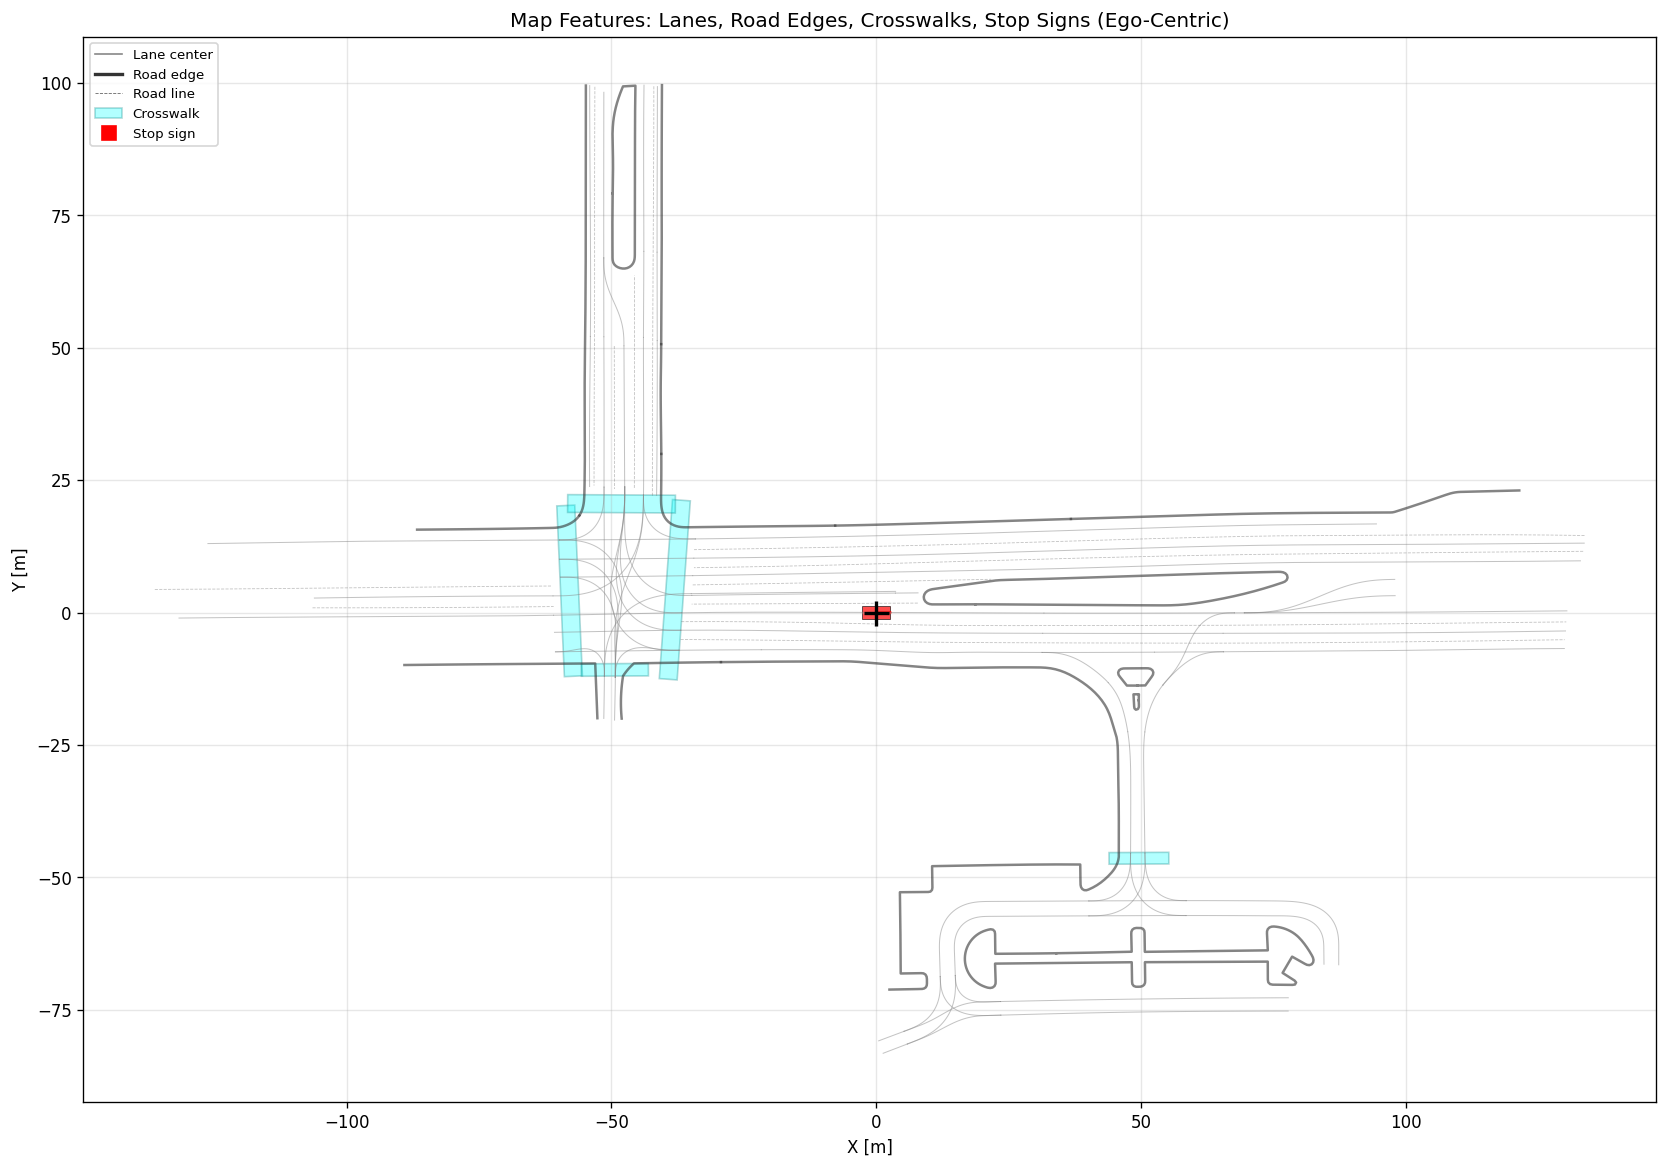

In [86]:
fig, ax = plt.subplots(1, 1, figsize=(14, 14))
ax.set_aspect('equal')
ax.set_title('Map Features: Lanes, Road Edges, Crosswalks, Stop Signs (Ego-Centric)')

# Lanes
for mf in lanes_list:
    pts = get_map_feature_polyline(mf.lane)
    if np.linalg.norm(pts.mean(axis=0) - sdc_pos) > 100:
        continue
    lx, ly = to_ego_frame(pts[:, 0], pts[:, 1])
    ax.plot(lx, ly, '-', color='#888888', linewidth=0.6, alpha=0.5)

# Road edges
for mf in road_edges_list:
    pts = get_map_feature_polyline(mf.road_edge)
    if np.linalg.norm(pts.mean(axis=0) - sdc_pos) > 100:
        continue
    lx, ly = to_ego_frame(pts[:, 0], pts[:, 1])
    ax.plot(lx, ly, '-', color='#333333', linewidth=1.5, alpha=0.6)

# Road lines
for mf in road_lines_list:
    pts = get_map_feature_polyline(mf.road_line)
    if np.linalg.norm(pts.mean(axis=0) - sdc_pos) > 100:
        continue
    lx, ly = to_ego_frame(pts[:, 0], pts[:, 1])
    ax.plot(lx, ly, '--', color='#666666', linewidth=0.5, alpha=0.4)

# Crosswalks
for mf in crosswalks_list:
    pts = get_map_feature_polyline(mf.crosswalk)
    if np.linalg.norm(pts.mean(axis=0) - sdc_pos) > 100:
        continue
    lx, ly = to_ego_frame(pts[:, 0], pts[:, 1])
    polygon = plt.Polygon(np.column_stack([lx, ly]), closed=True,
                          facecolor='cyan', edgecolor='teal', alpha=0.3, linewidth=1)
    ax.add_patch(polygon)

# Stop signs
for mf in stop_signs_list:
    pos = mf.stop_sign.position
    lx, ly = to_ego_frame(np.array([pos.x]), np.array([pos.y]))
    if np.sqrt(lx[0]**2 + ly[0]**2) > 100:
        continue
    ax.plot(lx[0], ly[0], 's', color='red', markersize=8, markeredgecolor='darkred', markeredgewidth=1)

# SDC
draw_oriented_box(ax, 0, 0, 0, sdc_w[ct], sdc_len[ct], color='red', alpha=0.7)
ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2)

legend_elements = [
    Line2D([0], [0], color='#888888', linewidth=1, label='Lane center'),
    Line2D([0], [0], color='#333333', linewidth=2, label='Road edge'),
    Line2D([0], [0], color='#666666', linewidth=0.5, linestyle='--', label='Road line'),
    plt.Rectangle((0,0), 1, 1, fc='cyan', ec='teal', alpha=0.3, label='Crosswalk'),
    Line2D([0], [0], marker='s', color='red', markersize=8, linestyle='', label='Stop sign'),
]
ax.legend(handles=legend_elements, fontsize=8, loc='upper left')
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Synthesize Route from SDC Future Trajectory

WOMD has no route concept. We synthesize route lanes by projecting SDC future trajectory
points onto the nearest lane center and collecting those lanes.

In [87]:
def find_nearest_lanes_for_trajectory(traj_x, traj_y, lanes_list, map_features_by_id, max_dist=10.0):
    """Find the nearest lane for each trajectory point.
    
    Returns: ordered list of unique lane feature IDs that form the route.
    """
    # Precompute lane center polylines
    lane_polys = []
    for mf in lanes_list:
        pts = get_map_feature_polyline(mf.lane)
        lane_polys.append((mf.id, pts))
    
    route_lane_ids = []
    seen = set()
    
    for px, py in zip(traj_x, traj_y):
        best_dist = max_dist
        best_id = None
        for lane_id, pts in lane_polys:
            dists = np.sqrt((pts[:, 0] - px)**2 + (pts[:, 1] - py)**2)
            min_dist = dists.min()
            if min_dist < best_dist:
                best_dist = min_dist
                best_id = lane_id
        if best_id is not None and best_id not in seen:
            route_lane_ids.append(best_id)
            seen.add(best_id)
    
    return route_lane_ids


# Use SDC future trajectory to find route lanes
future_valid = sdc_valid[ct+1:]
future_x = sdc_x[ct+1:][future_valid]
future_y = sdc_y[ct+1:][future_valid]

# Sample every 10 frames to speed up
sample_idx = np.arange(0, len(future_x), 10)
route_ids = find_nearest_lanes_for_trajectory(
    future_x[sample_idx], future_y[sample_idx], lanes_list, map_features_by_id
)

print(f"Synthesized route: {len(route_ids)} unique lanes")
print(f"  (nuPlan route_lanes has max 25 lanes)")
for i, lid in enumerate(route_ids[:10]):
    print(f"  Lane {i}: ID={lid}")

Synthesized route: 3 unique lanes
  (nuPlan route_lanes has max 25 lanes)
  Lane 0: ID=517
  Lane 1: ID=528
  Lane 2: ID=453


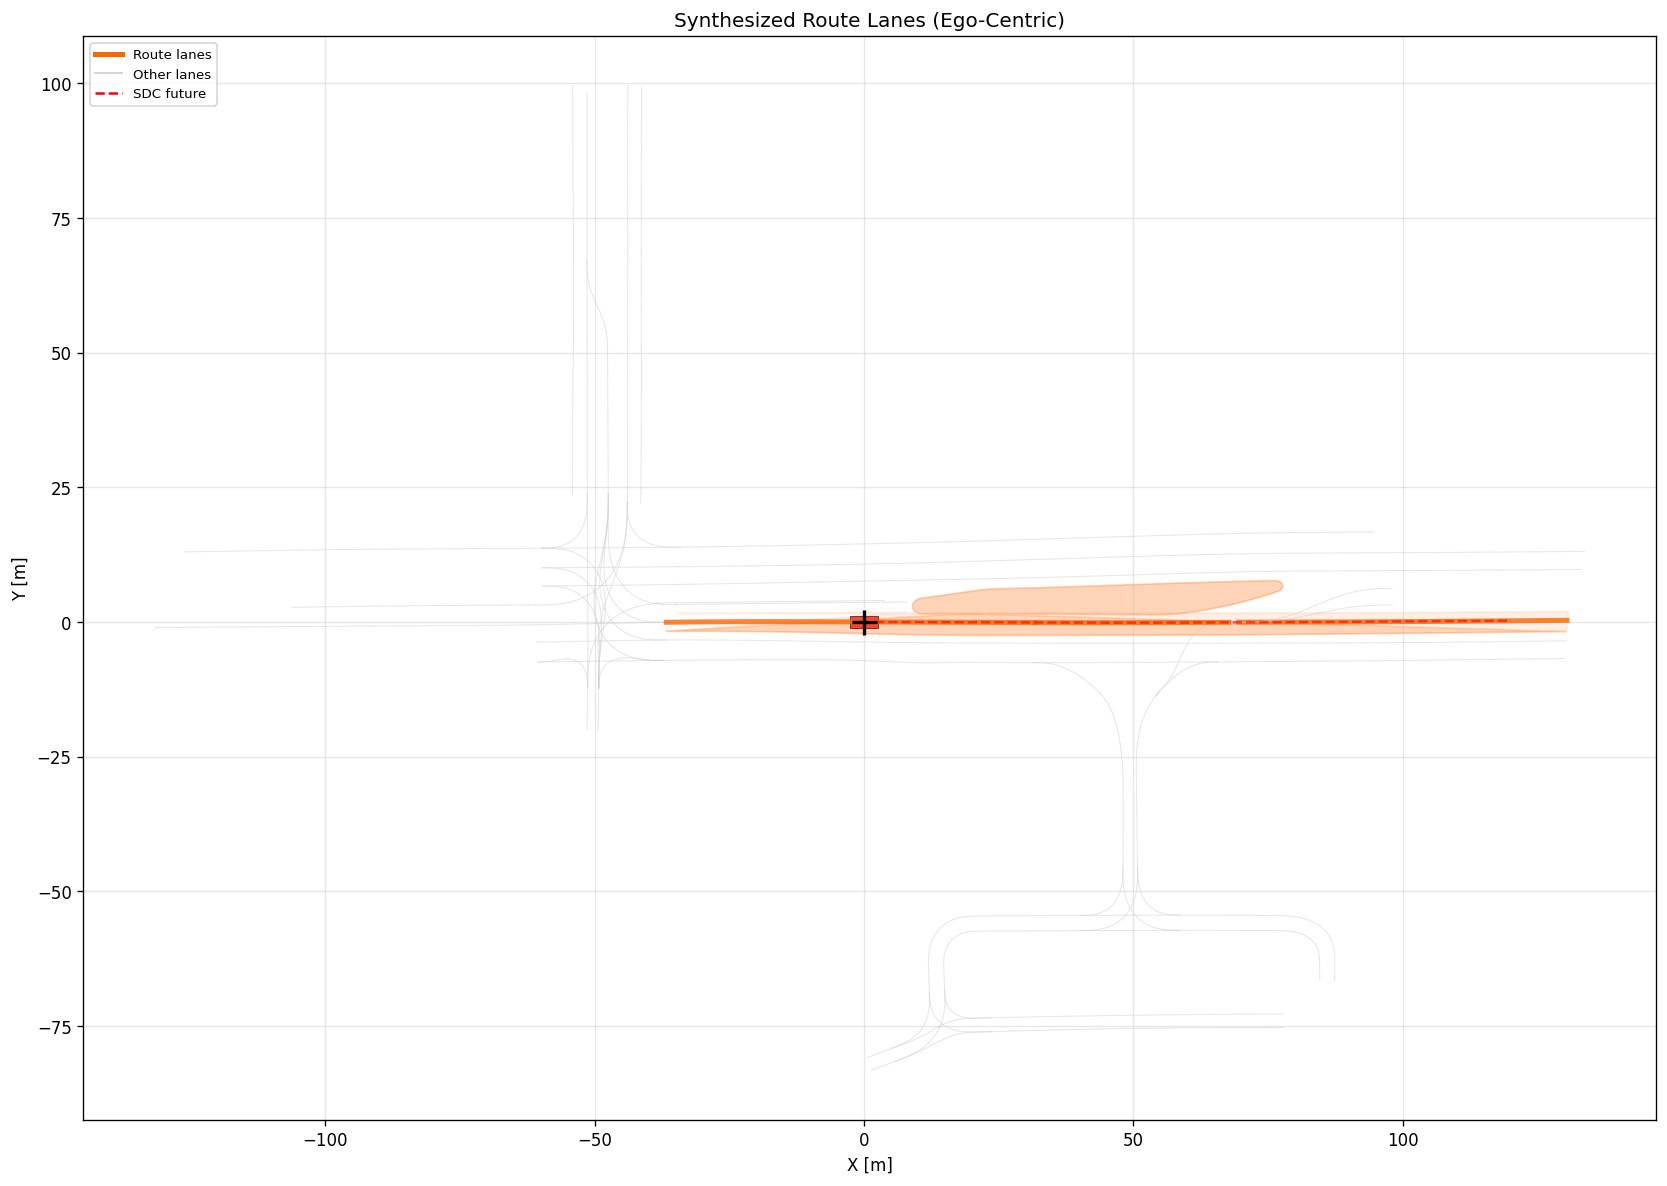

In [88]:
fig, ax = plt.subplots(1, 1, figsize=(14, 14))
ax.set_aspect('equal')
ax.set_title('Synthesized Route Lanes (Ego-Centric)')

route_id_set = set(route_ids)

# Background lanes
for mf in lanes_list:
    pts = get_map_feature_polyline(mf.lane)
    if np.linalg.norm(pts.mean(axis=0) - sdc_pos) > 100:
        continue
    lx, ly = to_ego_frame(pts[:, 0], pts[:, 1])
    
    if mf.id in route_id_set:
        ax.plot(lx, ly, '-', color='#ff6600', linewidth=3.0, alpha=0.8)
        # Fill lane area
        left, right, _ = resolve_lane_boundaries(mf, map_features_by_id)
        if left is not None and right is not None:
            blx, bly = to_ego_frame(left[:, 0], left[:, 1])
            brx, bry = to_ego_frame(right[:, 0], right[:, 1])
            ax.fill(np.concatenate([blx, brx[::-1]]),
                    np.concatenate([bly, bry[::-1]]),
                    color='#ff6600', alpha=0.1)
    else:
        ax.plot(lx, ly, '-', color='#cccccc', linewidth=0.6, alpha=0.5)

# SDC future trajectory
fut_lx, fut_ly = to_ego_frame(future_x, future_y)
ax.plot(fut_lx, fut_ly, 'r--', linewidth=1.5, alpha=0.6, label='SDC future')

# SDC
draw_oriented_box(ax, 0, 0, 0, sdc_w[ct], sdc_len[ct], color='red', alpha=0.7, label='SDC')
ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2)

legend_elements = [
    Line2D([0], [0], color='#ff6600', linewidth=3, label='Route lanes'),
    Line2D([0], [0], color='#cccccc', linewidth=1, label='Other lanes'),
    Line2D([0], [0], color='red', linewidth=1.5, linestyle='--', label='SDC future'),
]
ax.legend(handles=legend_elements, fontsize=8, loc='upper left')
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Full Scene Overview

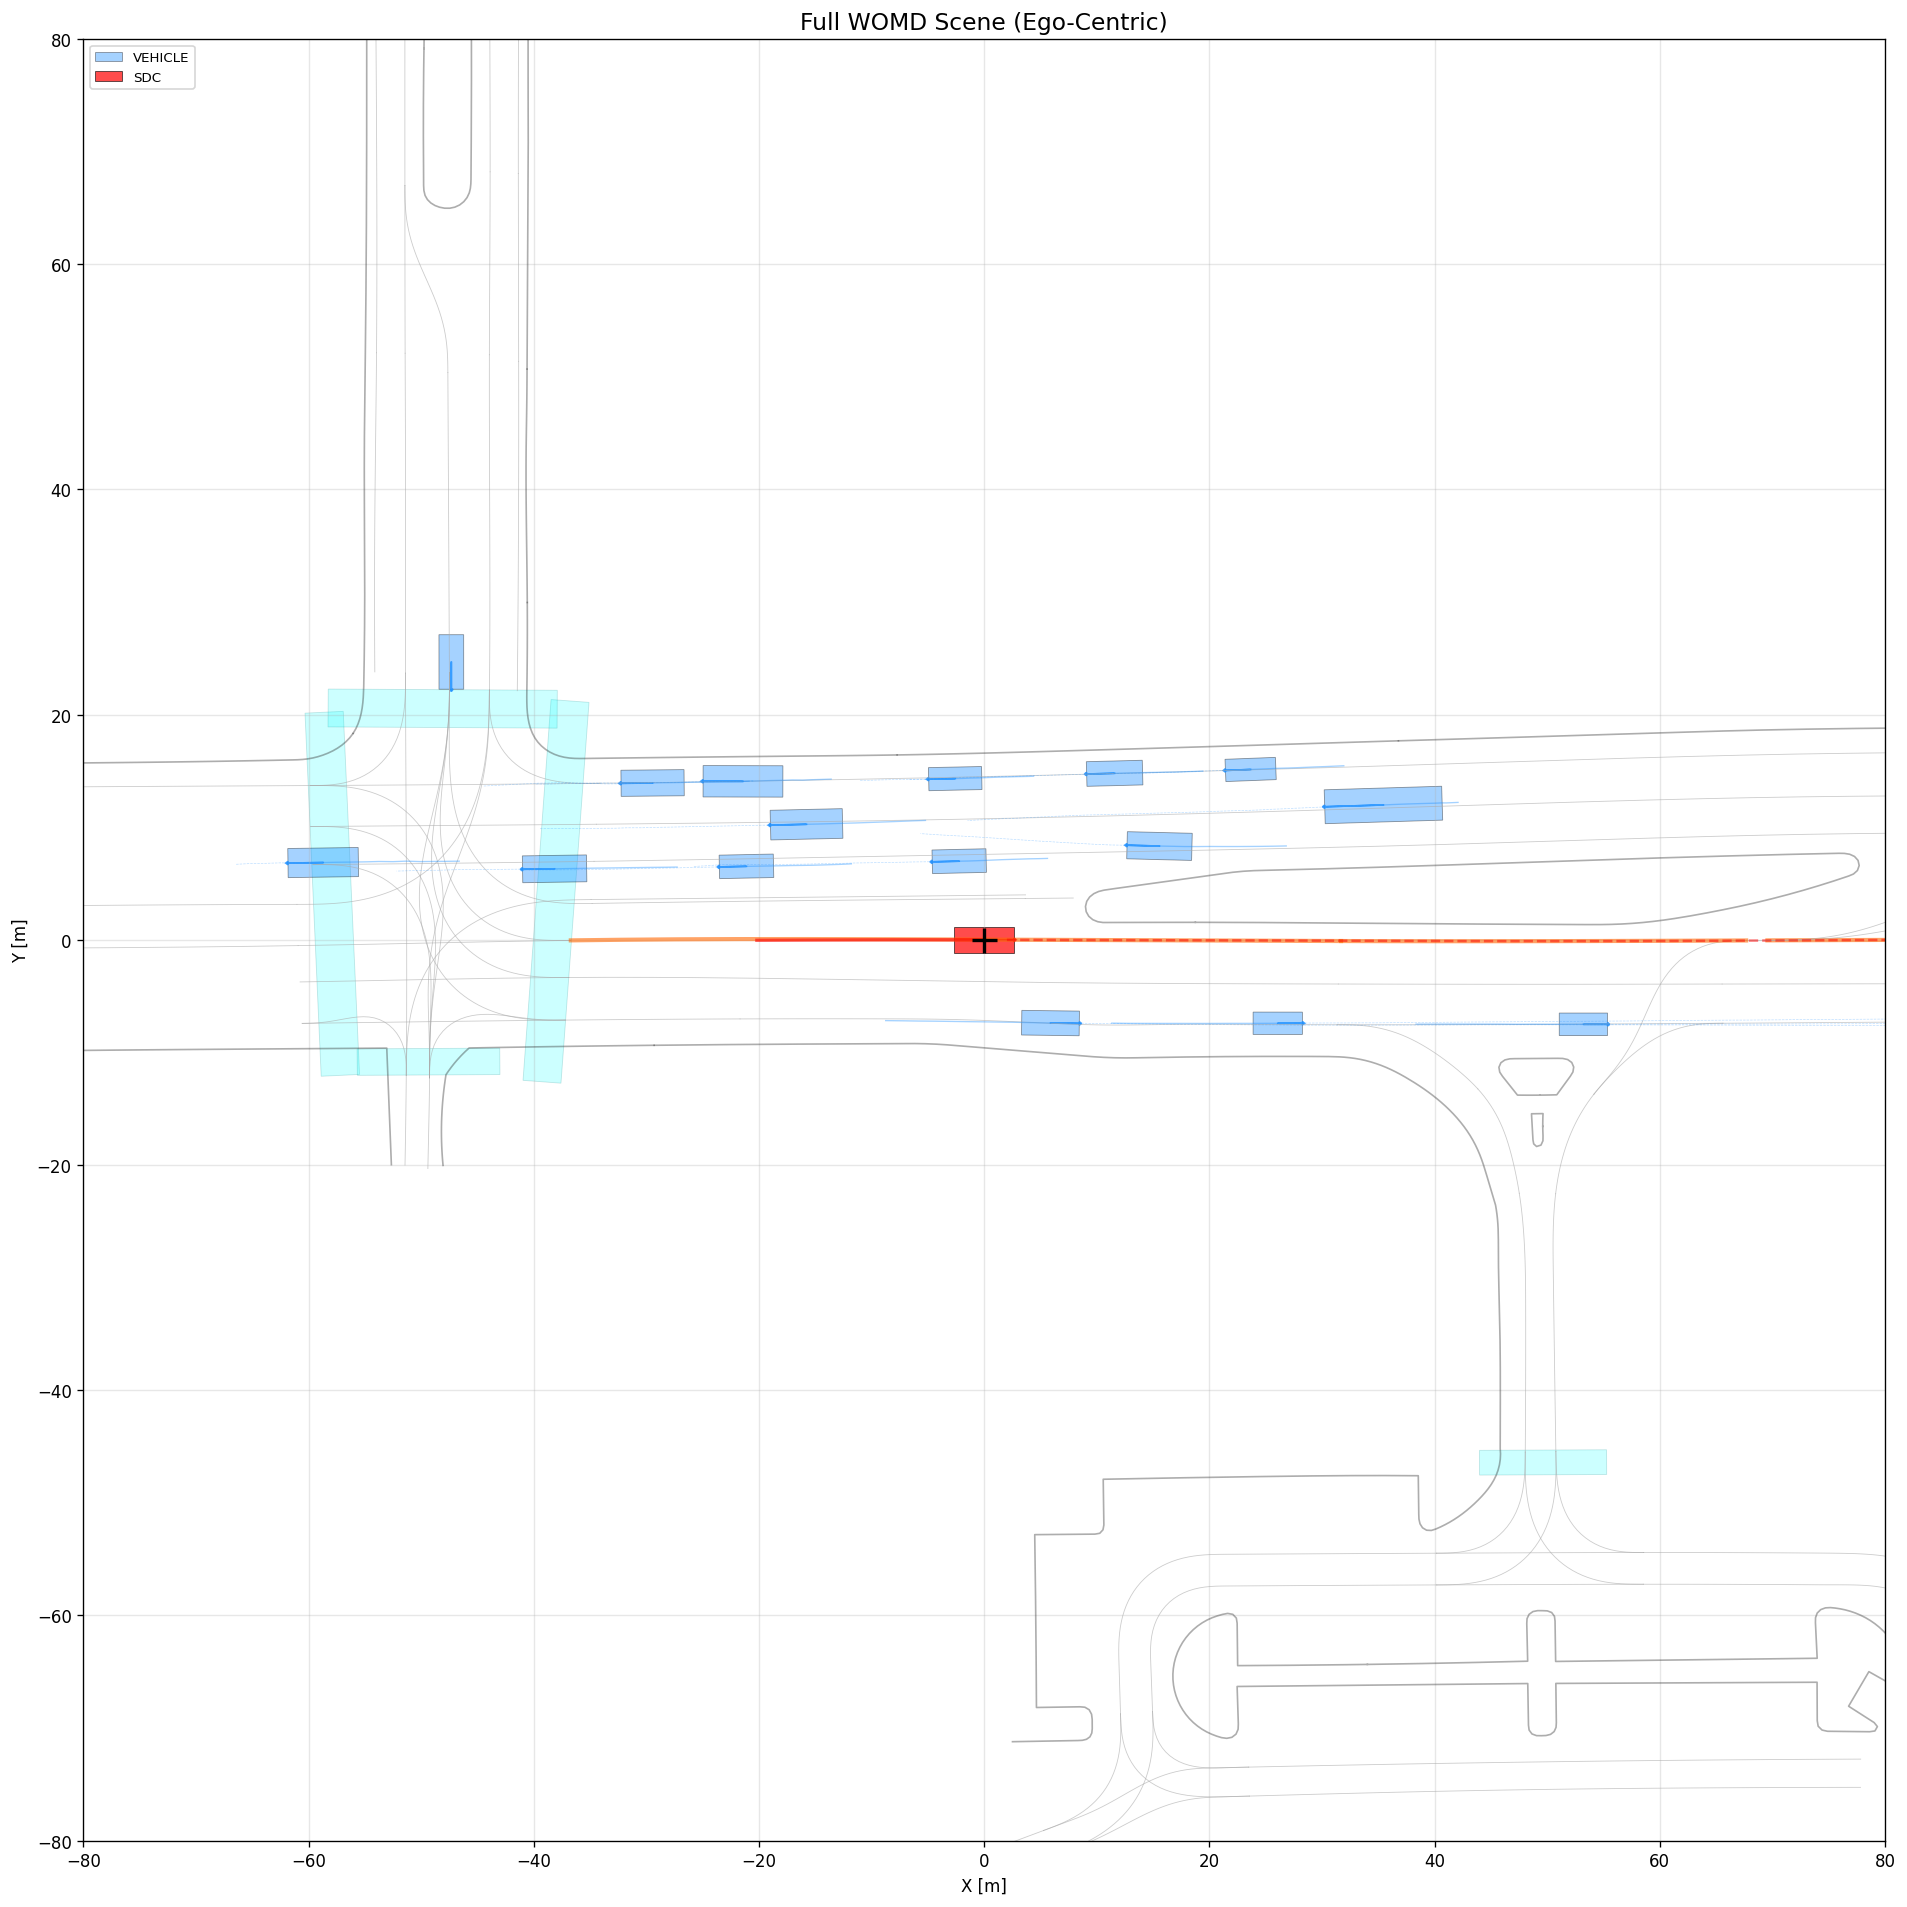

In [89]:
fig, ax = plt.subplots(1, 1, figsize=(16, 16))
ax.set_aspect('equal')
ax.set_title('Full WOMD Scene (Ego-Centric)', fontsize=14)

# --- Road edges ---
for mf in road_edges_list:
    pts = get_map_feature_polyline(mf.road_edge)
    if np.linalg.norm(pts.mean(axis=0) - sdc_pos) > 100:
        continue
    lx, ly = to_ego_frame(pts[:, 0], pts[:, 1])
    ax.plot(lx, ly, '-', color='#333333', linewidth=1.0, alpha=0.4)

# --- Lanes with TL coloring ---
for mf in lanes_list:
    pts = get_map_feature_polyline(mf.lane)
    if np.linalg.norm(pts.mean(axis=0) - sdc_pos) > 100:
        continue
    lx, ly = to_ego_frame(pts[:, 0], pts[:, 1])
    
    if mf.id in tl_at_current:
        state = tl_at_current[mf.id]['state']
        color = TL_COLORS[state]
        lw = 2.0
    elif mf.id in route_id_set:
        color = '#ff6600'
        lw = 2.5
    else:
        color = '#aaaaaa'
        lw = 0.5
    ax.plot(lx, ly, '-', color=color, linewidth=lw, alpha=0.6)

# --- Crosswalks ---
for mf in crosswalks_list:
    pts = get_map_feature_polyline(mf.crosswalk)
    if np.linalg.norm(pts.mean(axis=0) - sdc_pos) > 100:
        continue
    lx, ly = to_ego_frame(pts[:, 0], pts[:, 1])
    polygon = plt.Polygon(np.column_stack([lx, ly]), closed=True,
                          facecolor='cyan', edgecolor='teal', alpha=0.2, linewidth=0.5)
    ax.add_patch(polygon)

# --- Stop signs ---
for mf in stop_signs_list:
    pos = mf.stop_sign.position
    lx, ly = to_ego_frame(np.array([pos.x]), np.array([pos.y]))
    if np.sqrt(lx[0]**2 + ly[0]**2) > 100:
        continue
    ax.plot(lx[0], ly[0], 's', color='red', markersize=6, markeredgecolor='darkred')

# --- Agents ---
legend_added3 = set()
for obj_type, tracks in tracks_by_type.items():
    color = OBJECT_COLORS.get(obj_type, 'gray')
    for track_idx, track in tracks:
        x, y, h, vx, vy, l, w, valid = get_track_states(track)
        lx, ly = to_ego_frame(x, y)
        if np.sqrt(lx[ct]**2 + ly[ct]**2) > 80:
            continue
        
        past_v = valid[:ct+1]
        lbl = obj_type if obj_type not in legend_added3 else None
        ax.plot(lx[:ct+1][past_v], ly[:ct+1][past_v], '-', color=color, linewidth=0.8, alpha=0.4)
        if valid[ct]:
            local_heading = h[ct] - ego_h
            draw_oriented_box(ax, lx[ct], ly[ct], local_heading, w[ct], l[ct],
                              color=color, alpha=0.4, label=lbl)
        fut_v = valid[ct+1:]
        if fut_v.any():
            ax.plot(lx[ct+1:][fut_v], ly[ct+1:][fut_v], '--', color=color, linewidth=0.4, alpha=0.3)
        legend_added3.add(obj_type)

# --- SDC ---
ax.plot(sdc_lx[:ct+1][past_mask], sdc_ly[:ct+1][past_mask], 'r-', linewidth=2, alpha=0.6)
ax.plot(sdc_lx[ct+1:][future_mask], sdc_ly[ct+1:][future_mask], 'r--', linewidth=1.5, alpha=0.5)
draw_oriented_box(ax, 0, 0, 0, sdc_w[ct], sdc_len[ct], color='red', alpha=0.7, label='SDC')

ax.plot(0, 0, 'k+', markersize=15, markeredgewidth=2)
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.legend(fontsize=8, loc='upper left')
ax.grid(True, alpha=0.3)
ax.set_xlim(-80, 80)
ax.set_ylim(-80, 80)
plt.tight_layout()
plt.show()

## 10. Key Findings & Mapping Verification Summary

In [90]:
print("=" * 70)
print("WOMD -> nuPlan MAPPING VERIFICATION SUMMARY")
print("=" * 70)

print("\n1. COORDINATE SYSTEM")
print(f"   WOMD: Global frame (X=East, Y=North)")
print(f"   nuPlan: Ego-centric frame")
print(f"   Action: Transform using SDC pose at current_time_index")
print(f"   SDC current pose: ({sdc_x[ct]:.2f}, {sdc_y[ct]:.2f}, {sdc_h[ct]:.4f})")

print("\n2. HISTORY LENGTH")
print(f"   WOMD: {ct+1} frames ({ct*0.1:.1f}s including current)")
print(f"   nuPlan: 21 frames (2.0s including current)")
print(f"   Action: Pad first {21-(ct+1)} frames by repeating earliest valid state")

print("\n3. FUTURE LENGTH")
print(f"   WOMD: {len(sdc_track.states)-ct-1} frames ({(len(sdc_track.states)-ct-1)*0.1:.1f}s)")
print(f"   nuPlan: 80 frames (8.0s)")
print(f"   Status: Direct match")

print("\n4. LANE BOUNDARIES")
total_left = sum(1 for mf in lanes_list if len(mf.lane.left_boundaries) > 0)
total_right = sum(1 for mf in lanes_list if len(mf.lane.right_boundaries) > 0)
print(f"   Lanes with left boundary: {total_left}/{len(lanes_list)}")
print(f"   Lanes with right boundary: {total_right}/{len(lanes_list)}")
print(f"   Resolution: via BoundarySegment -> RoadLine/RoadEdge polyline[start:end]")
print(f"   nuPlan format: boundary offset = boundary_point - center_point")

print("\n5. TRAFFIC LIGHTS")
print(f"   WOMD: {len(tl_at_current)} lanes with TL state")
print(f"   Mapping: GO/ARROW_GO -> green[1,0,0,0]")
print(f"            CAUTION/ARROW_CAUTION/FLASHING_CAUTION -> yellow[0,1,0,0]")
print(f"            STOP/ARROW_STOP/FLASHING_STOP -> red[0,0,1,0]")
print(f"            UNKNOWN -> unknown[0,0,0,1]")

print("\n6. ROUTE LANES")
print(f"   WOMD: No route concept")
print(f"   Synthetic route: {len(route_ids)} lanes from SDC future projection")
print(f"   nuPlan max: 25 route lanes")

print("\n7. STATIC OBJECTS")
print(f"   WOMD: {len(stop_signs_list)} stop_signs, {len(crosswalks_list)} crosswalks, {len(speed_bumps_list)} speed_bumps")
print(f"   nuPlan: 5 slots for [czone_sign, barrier, cone, generic]")
print(f"   Action: Fill with stop_sign positions, zero-pad remainder")

print("\n8. AGENT TYPES")
print(f"   WOMD: VEHICLE(1), PEDESTRIAN(2), CYCLIST(3), OTHER(4)")
print(f"   nuPlan: VEHICLE[1,0,0], PEDESTRIAN[0,1,0], BICYCLE[0,0,1]")
print(f"   Action: CYCLIST -> BICYCLE, ignore OTHER")

print("\n9. MISSING FIELDS")
print(f"   Acceleration: compute via velocity finite difference")
print(f"   Steering angle: compute via heading finite difference")
print(f"   Yaw rate: compute via heading finite difference")

print("\n10. SPEED LIMIT")
print(f"    WOMD: mph, nuPlan: m/s")
print(f"    Action: multiply by 0.44704")

print("\n" + "=" * 70)

WOMD -> nuPlan MAPPING VERIFICATION SUMMARY

1. COORDINATE SYSTEM
   WOMD: Global frame (X=East, Y=North)
   nuPlan: Ego-centric frame
   Action: Transform using SDC pose at current_time_index
   SDC current pose: (-8725.75, -3450.22, -0.0045)

2. HISTORY LENGTH
   WOMD: 11 frames (1.0s including current)
   nuPlan: 21 frames (2.0s including current)
   Action: Pad first 10 frames by repeating earliest valid state

3. FUTURE LENGTH
   WOMD: 80 frames (8.0s)
   nuPlan: 80 frames (8.0s)
   Status: Direct match

4. LANE BOUNDARIES
   Lanes with left boundary: 166/290
   Lanes with right boundary: 271/290
   Resolution: via BoundarySegment -> RoadLine/RoadEdge polyline[start:end]
   nuPlan format: boundary offset = boundary_point - center_point

5. TRAFFIC LIGHTS
   WOMD: 6 lanes with TL state
   Mapping: GO/ARROW_GO -> green[1,0,0,0]
            CAUTION/ARROW_CAUTION/FLASHING_CAUTION -> yellow[0,1,0,0]
            STOP/ARROW_STOP/FLASHING_STOP -> red[0,0,1,0]
            UNKNOWN -> unknow